# c8 · Step 8: Regularisation

Both architecture candidates from c7 (the best **small** and the best **deep** model) are regularised, because
the benefit of regularisation depends on how much a model overfits. Order: augmentation → weight decay →
dropout, each starting from the previous winner.

| # | Technique | Options |
|---|---|---|
| 1 | augmentation (train only, on the GPU) | **none**, geometric, mild (geometric + intensity), strong |
| 2 | weight decay (decoupled, i.e. AdamW for Adam) | **0**, two strengths |
| 3 | dropout before the classifier | **0**, 0.3 |
| 4 | small vs deep | best regularised version of each |

All runs use the protocol from c4 (60-epoch cap, patience 20 on val balanced accuracy), which leaves augmented
runs, which learn more slowly, enough time. Seeds: 3 for the small model; 2 for the
deep model, because it is ~5-10x slower. The `compare` rule accounts for the smaller n with a wider threshold.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from dataclasses import replace
from lib.train import Config, run
from lib.report import run_seeds, compare, pick, log_progress, SEEDS3
from lib.data import ARTIFACTS
from lib.report import protocol; proto = protocol()   # c4 protocol with the raised epoch cap
INPUT = json.loads((ARTIFACTS / "input.json").read_text())
OPTIM = json.loads((ARTIFACTS / "optim.json").read_text())
ARCH = {k: {kk: tuple(vv) if isinstance(vv, list) else vv for kk, vv in v.items()}
        for k, v in json.loads((ARTIFACTS / "arch.json").read_text()).items()}
BASE = replace(Config(exp="c8", name="x", monitor=proto["monitor"], patience=proto["patience"], epochs=proto["epochs"]), **INPUT, **OPTIM)
CAND = {"small": (replace(BASE, **ARCH["small"]), SEEDS3), "deep": (replace(BASE, **ARCH["deep"]), SEEDS3[:2])}
print(OPTIM); print(ARCH)

{'optimizer': 'adam', 'lr': 0.03, 'batch_size': 64, 'schedule': 'none', 'loss': 'label_smoothing', 'sampler': 'none'}
{'small': {'widths': (16, 32, 64, 128), 'depths': (1, 1, 1, 1), 'kernel': 5, 'stem_kernel': 5, 'block': 'single', 'norm': True, 'residual': False, 'downsample': 'avgpool'}, 'deep': {'widths': (32, 64, 128, 256), 'depths': (2, 2, 2, 2), 'kernel': 5, 'stem_kernel': 5, 'block': 'basic', 'norm': True, 'residual': True, 'downsample': 'avgpool'}}


## 1. Augmentation

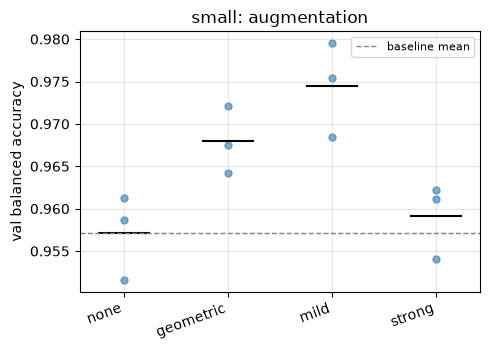

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep,train-val gap
none,0.9572,0.0050,3.0,0.0000,0.0505,0.9530,0.9966,0.9583,49.6667,276628.0,0.6585,0.0392
geometric,0.9680,0.0040,3.0,0.0108,0.0505,0.9644,0.9977,0.9757,60.0000,276628.0,0.7139,0.0294
mild,0.9744,0.0056,3.0,0.0173,0.0505,0.9725,0.9981,0.9722,59.3333,276628.0,0.7355,0.0203
strong,0.9591,0.0045,3.0,0.0019,0.0505,0.9524,0.9957,0.9653,60.0000,276628.0,1.0001,0.0223


small -> chosen augmentation: mild


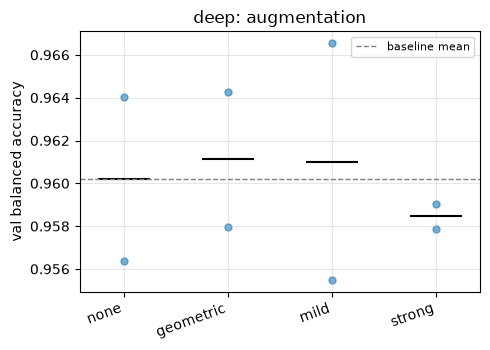

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep,train-val gap
none,0.9602,0.0054,2.0,0.0000,0.0619,0.9584,0.9952,0.9584,58.5,7678436.0,3.8988,0.0388
geometric,0.9611,0.0045,2.0,0.0009,0.0619,0.9583,0.9894,0.9584,60.0,7678436.0,3.9380,0.0336
mild,0.9610,0.0078,2.0,0.0008,0.0619,0.9565,0.9963,0.9636,54.0,7678436.0,3.9618,0.0262
strong,0.9585,0.0008,2.0,-0.0017,0.0619,0.9512,0.9933,0.9584,60.0,7678436.0,4.1106,0.0267


deep -> chosen augmentation: geometric


In [2]:
def gap(rs):  # train minus val balanced accuracy at the selected epoch (overfitting indicator)
    return np.mean([r["history"][r["best_epoch"] - 1]["train_bal_acc"] - r["val"]["bal_acc"] for r in rs])

aug_runs, chosen, tables = {}, {}, {}
for m, (cfg, seeds) in CAND.items():
    aug_runs[m] = {a: run_seeds(replace(cfg, name=f"{m}_aug_{a}", aug=a), seeds) for a in ["none", "geometric", "mild", "strong"]}
    tables[m] = compare(aug_runs[m], "none", f"{m}: augmentation")
    tables[m]["train-val gap"] = [round(gap(rs), 4) for rs in aug_runs[m].values()]
    display(tables[m])
    chosen[m] = pick(tables[m], "none")
    print(m, "-> chosen augmentation:", chosen[m])

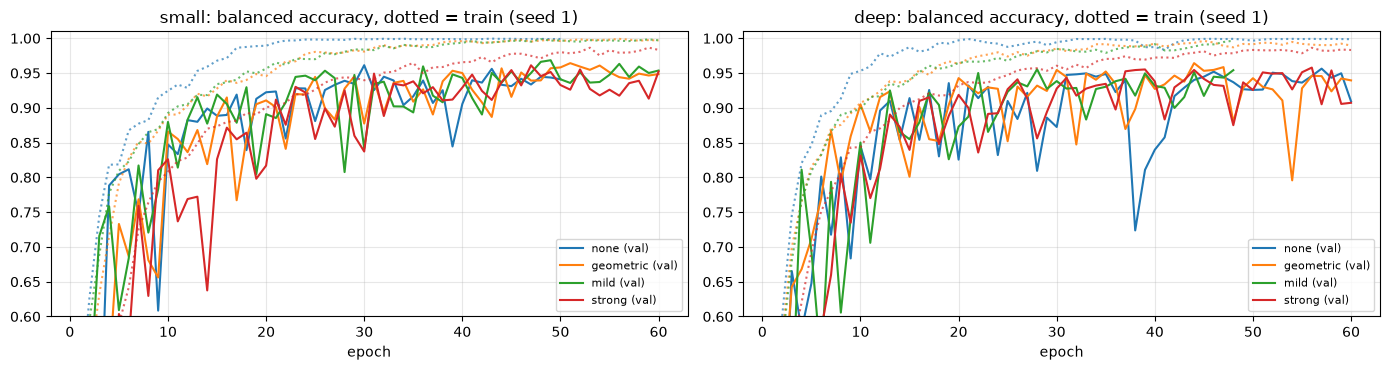

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, m in zip(axes, CAND):
    for a, rs in aug_runs[m].items():
        h = pd.DataFrame(rs[0]["history"])
        l, = ax.plot(h.epoch, h.val_bal_acc, label=f"{a} (val)")
        ax.plot(h.epoch, h.train_bal_acc, ls=":", color=l.get_color(), alpha=0.7)
    ax.set(title=f"{m}: balanced accuracy, dotted = train (seed 1)", xlabel="epoch", ylim=(0.6, 1.01)); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Result** (val balanced accuracy, train-val gap in brackets):

| augmentation | small (3 seeds) | deep (2 seeds) |
|---|---|---|
| none | 0.957 (0.039) | 0.960 (0.039) |
| geometric | 0.968 (0.029) | **0.961** (0.034) |
| mild | **0.974** (0.020) | 0.961 (0.026) |
| strong | 0.959 (0.022) | 0.959 (0.027) |

Augmentation is the largest single gain for the small model (+1.7 pp with mild) and halves its train-val gap.
The deep model barely moves (all four within 0.3 pp), although augmentation does shrink its train-val gap.
Augmented runs used the full 60 epochs; round r3 gave them up to 200 and they did not score higher (small with
geometric augmentation: 0.968 in both rounds), so the 60-epoch cap is not what limits them.

**Decision: small: mild; deep: geometric** (highest mean each; for the deep model the options are a tie in all
but name).

*Other rounds.* r1 (tie rule) measured +1.2 pp (small) and +1.8 pp (deep) for geometric and kept no augmentation.
r3 (200-epoch cap) chose geometric for small (0.968) and none for deep (0.956).

## 2. Weight decay

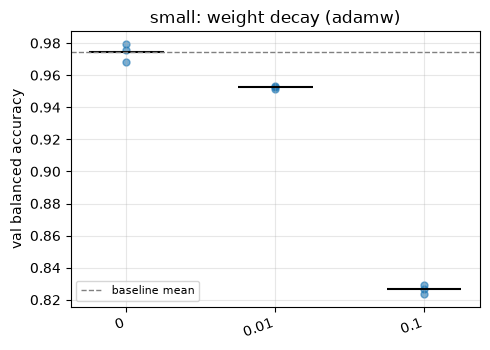

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0,0.9744,0.0056,3.0,0.0000,0.0505,0.9725,0.9981,0.9722,59.3333,276628.0,0.7355
0.01,0.9525,0.0011,3.0,-0.0220,0.0505,0.9462,0.9970,0.9618,58.6667,276628.0,0.7350
0.1,0.8266,0.0030,3.0,-0.1479,0.0505,0.8041,0.9768,0.8819,43.3333,276628.0,0.7369


small -> chosen weight decay: 0


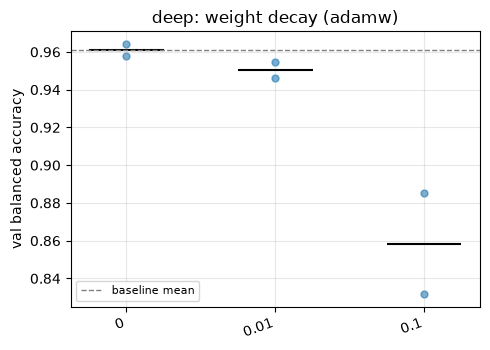

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0,0.9611,0.0045,2.0,0.0000,0.0619,0.9583,0.9894,0.9584,60.0,7678436.0,3.9380
0.01,0.9504,0.0057,2.0,-0.0107,0.0619,0.9481,0.9963,0.9427,55.5,7678436.0,3.9511
0.1,0.8584,0.0377,2.0,-0.1028,0.0619,0.8349,0.9803,0.9218,39.0,7678436.0,3.8549


deep -> chosen weight decay: 0


In [4]:
WD = [0.01, 0.1] if OPTIM["optimizer"] in ("adam", "adamw") else [5e-4, 5e-3]
wd_runs = {}
for m, (cfg, seeds) in CAND.items():
    cfg = replace(cfg, aug=chosen[m]); CAND[m] = (cfg, seeds)
    opt = "adamw" if OPTIM["optimizer"] in ("adam", "adamw") else OPTIM["optimizer"]
    wd_runs[m] = {"0": aug_runs[m][chosen[m]],
                  **{f"{w:g}": run_seeds(replace(cfg, name=f"{m}_aug_{chosen[m]}_wd{w:g}", optimizer=opt, weight_decay=w), seeds) for w in WD}}
    t = compare(wd_runs[m], "0", f"{m}: weight decay ({opt})"); display(t)
    w = pick(t, "0")
    if w != "0":
        CAND[m] = (replace(cfg, optimizer=opt, weight_decay=float(w)), seeds)
    print(m, "-> chosen weight decay:", w)

**Result.** small: 0 **0.974**, 0.01 0.953, 0.1 0.827. deep: 0 **0.961**, 0.01 0.950, 0.1 0.858.

**Decision: no weight decay** for both. With Adam, weight decay is an L2 term on the gradient, and together with
the high learning rate it only hurts here. (AdamW, decoupled weight decay, was not tested.)

*Other rounds.* No weight decay in every round.

## 3. Dropout

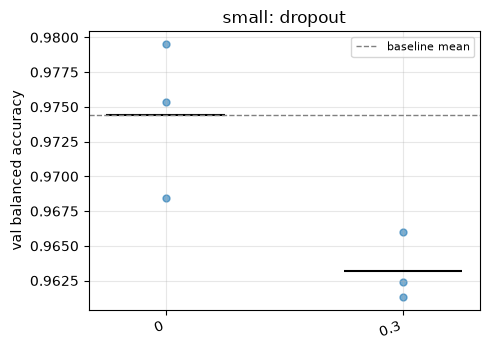

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0,0.9744,0.0056,3.0,0.0000,0.0505,0.9725,0.9981,0.9722,59.3333,276628.0,0.7355
0.3,0.9632,0.0024,3.0,-0.0112,0.0505,0.9626,0.9973,0.9410,60.0000,276628.0,0.7346


small -> chosen dropout: 0


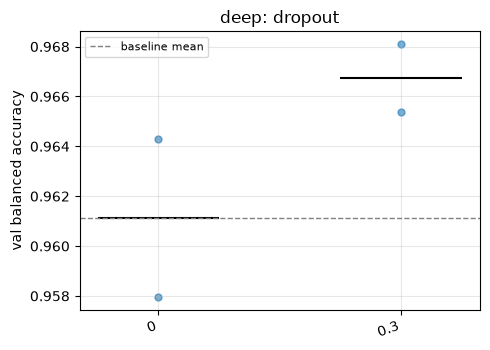

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0,0.9611,0.0045,2.0,0.0000,0.0619,0.9583,0.9894,0.9584,60.0,7678436.0,3.9380
0.3,0.9667,0.0019,2.0,0.0056,0.0619,0.9649,0.9966,0.9427,60.0,7678436.0,3.9427


deep -> chosen dropout: 0.3


In [5]:
do_runs = {}
for m, (cfg, seeds) in CAND.items():
    cur = wd_runs[m]["0" if cfg.weight_decay == 0 else f"{cfg.weight_decay:g}"]
    do_runs[m] = {"0": cur, "0.3": run_seeds(replace(cfg, name=f"{m}_aug_{cfg.aug}_wd{cfg.weight_decay:g}_do0.3", dropout=0.3), seeds)}
    t = compare(do_runs[m], "0", f"{m}: dropout"); display(t)
    d = pick(t, "0")
    if d != "0":
        CAND[m] = (replace(cfg, dropout=0.3), seeds)
    print(m, "-> chosen dropout:", d)

**Result.** small: 0 **0.974**, 0.3 0.963. deep: 0 0.961, 0.3 **0.967**.

**Decision: small: no dropout; deep: dropout 0.3** (highest mean each). Dropout helps only the large model, which
is the expected direction.

*Other rounds.* r1 and r3: no dropout for either model.

## 4. Small vs deep, both regularised

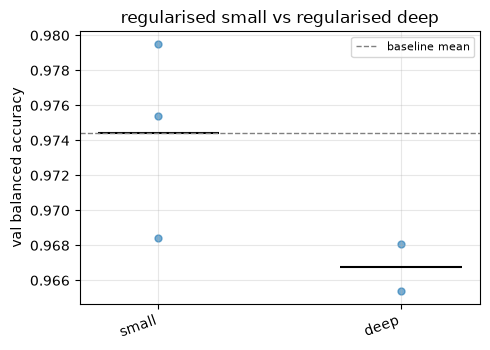

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
small,0.9744,0.0056,3.0,0.0000,0.0505,0.9725,0.9981,0.9722,59.3333,276628.0,0.7355
deep,0.9667,0.0019,2.0,-0.0077,0.0565,0.9649,0.9966,0.9427,60.0000,7678436.0,3.9427


small per-class recall: {'glioma': 0.972, 'meningioma': 0.963, 'no_tumor': 0.972, 'pituitary': 0.99}
deep per-class recall: {'glioma': 0.971, 'meningioma': 0.97, 'no_tumor': 0.943, 'pituitary': 0.983}


In [6]:
final = {m: do_runs[m]["0.3" if cfg.dropout else "0"] for m, (cfg, _) in CAND.items()}
t = compare(final, "small", "regularised small vs regularised deep"); display(t)
for m, rs in final.items():
    print(m, "per-class recall:", pd.DataFrame([r["val"]["recall"] for r in rs]).mean().round(3).to_dict())

**Result.** Regularised small 0.974 (3 seeds, 277k parameters, 0.7 s/epoch) vs regularised deep 0.967 (2 seeds,
7.7M parameters, 3.9 s/epoch). Per-class recall: small is better on no_tumor (0.972 vs 0.943), the deep model
slightly better on meningioma (0.970 vs 0.963).

**Decision: small** (highest mean). The selection rule ignores size, but the small model also happens to be
28x smaller and 5x faster.

## Decisions

| | small (plain 5) | deep (residual 17, width 32) |
|---|---|---|
| augmentation | mild | geometric |
| weight decay | 0 | 0 |
| dropout | 0 | 0.3 |
| mean val bal. acc | **0.974** | 0.967 |

**Winner: small** (0.974, from 0.959 after c7). Augmentation gave the gain; weight decay hurt; dropout helped only
the large model.

**Across rounds.** r1 (tie rule): nothing adopted, small 0.935, deep 0.949. r3 (200-epoch cap): small (residual
9, geometric augmentation) 0.968, deep (residual 17, width 16, no augmentation) 0.956. In every round the small
model won.

In [7]:
WINNER = pick(t, "small")   # highest mean val balanced accuracy wins, whatever its size
cfg = CAND[WINNER][0]
REG = dict(aug=cfg.aug, optimizer=cfg.optimizer, weight_decay=cfg.weight_decay, dropout=cfg.dropout)
_ = (ARTIFACTS / "reg.json").write_text(json.dumps({"winner": WINNER, "arch": ARCH[WINNER], **REG}, default=list))
for m in CAND: _ = log_progress(f"c8 regularised {m}", final[m])
WINNER, REG

('small',
 {'aug': 'mild', 'optimizer': 'adam', 'weight_decay': 0.0, 'dropout': 0.0})